# Chapitre 14 - Cours 3 : cartes auto-organisatrices, ACP et ses extensions, ACI, MDS

Ce notebook couvre les sections 14.4 à 14.8 du livre : des méthodes qui cherchent une
**structure de petite dimension** (une variété, des sources cachées, une carte du plan)
rendant compte de données de grande dimension.

1. cartes auto-organisatrices de Kohonen (SOM, figures 14.15 à 14.18) ;
2. analyse en composantes principales (figures 14.20 à 14.24) ;
3. analyse de Procrustes et formes moyennes (figures 14.25, 14.26) ;
4. courbes principales (figure 14.27) ;
5. clustering spectral et ACP à noyau (figures 14.29, 14.30) ;
6. ACP parcimonieuse et factorisation en matrices positives (présentation) ;
7. analyse factorielle et analyse en composantes indépendantes (figures 14.37, 14.38) ;
8. positionnement multidimensionnel (MDS, figure 14.43).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch14_non_supervise as ns
set_style()

## 1. Cartes auto-organisatrices (section 14.4)

### 1.1 Principe

Une carte auto-organisatrice (*self-organizing map*, SOM) est une version **contrainte** des
K-means : les $K = q_1 q_2$ prototypes $m_j \in \mathbb{R}^p$ sont indexés par les nœuds
$\ell_j \in \{1..q_1\} \times \{1..q_2\}$ d'une grille du plan, et l'on veut que des nœuds voisins
sur la grille aient des prototypes proches dans $\mathbb{R}^p$. Image : des « boutons » cousus
régulièrement sur un tissu (initialement le plan des deux premières composantes principales),
que l'on déforme pour approcher au mieux les données.

**Algorithme (version en ligne).** Les observations sont traitées une par une. Pour $x_i$ :

1. on trouve le prototype le plus proche $m_j$ (distance euclidienne dans $\mathbb{R}^p$) ;
2. on déplace vers $x_i$ ce prototype **et ses voisins sur la grille** :
   $$m_k \leftarrow m_k + \alpha\,(x_i - m_k) \quad \text{pour tout } k \text{ tel que }
   \|\ell_j - \ell_k\| < r \qquad (14.46).$$

Le taux d'apprentissage $\alpha$ décroît (par exemple de 1 à 0) et le rayon $r$ de $R$ à 1 au fil
des itérations. Une variante pondère la mise à jour par $h(\|\ell_j - \ell_k\|)$, décroissante
de la distance sur la grille (14.47).

> **Intuition.** La distance qui définit le voisinage se mesure **sur la grille**, pas dans
> $\mathbb{R}^p$ : c'est ce qui force la carte à rester « lisse ». Si $r$ est si petit qu'un
> voisinage ne contient que le prototype gagnant, la SOM devient une version en ligne des
> K-means.

### 1.2 Données sur une demi-sphère (figure 14.15)

On simule 90 points en dimension 3, en trois groupes de 30 situés près de $(0,0,1)$ (groupe
rouge, le plus resserré en angle), $(1,0,0)$ et $(0,1,0)$, avec un bruit gaussien
d'écart-type 0,6 sur chaque coordonnée (détails dans l'exercice 14.5).

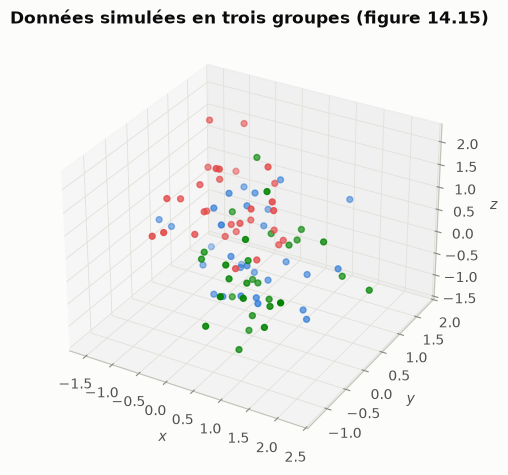

In [2]:
Xs, ys = ns.donnees_demi_sphere(rng=np.random.RandomState(0))
coul_s = np.array([COLORS[7], COLORS[5], COLORS[0]])[ys]
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
ax.scatter(*Xs.T, c=coul_s, s=18)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_zlabel("$z$")
ax.set_title("Données simulées en trois groupes (figure 14.15)")
plt.show()

On ajuste une grille $5 \times 5$ avec un rayon initial $R = 2$ (environ un tiers des prototypes
dans chaque voisinage), 40 passages sur les 90 observations (3600 itérations), $\alpha$ et $r$
décroissant linéairement.

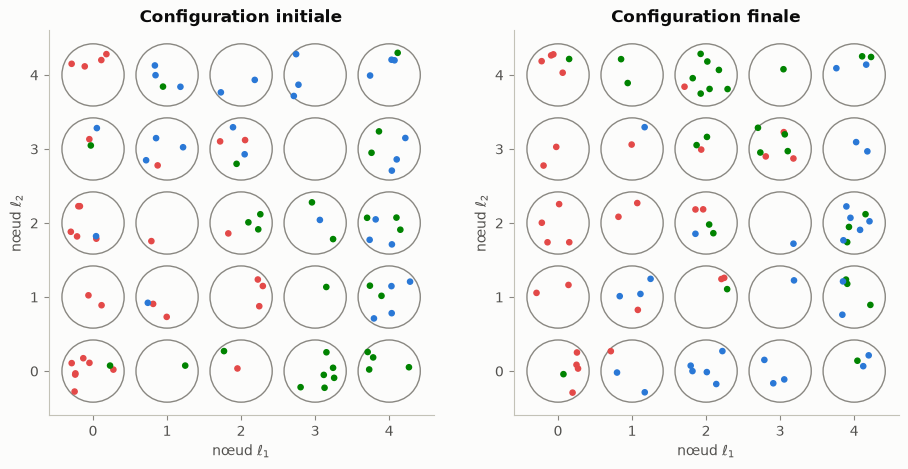

In [3]:
som0 = ns.init_som_acp(Xs, 5, 5)
res_som = ns.som(Xs, 5, 5, n_iter=3600, R=2.0, rng=np.random.RandomState(0), suivi=45)
lab_init = ns.distances_carrees(Xs, som0).argmin(1)


def dessiner_carte(ax, labels, grille, titre, rng):
    for (a, b) in grille:
        ax.add_patch(plt.Circle((a, b), 0.42, fill=False, color=GRAY))
    jit = rng.uniform(-0.3, 0.3, size=(len(labels), 2))
    pos = grille[labels] + jit
    ax.scatter(*pos.T, c=coul_s, s=14)
    ax.set_xlim(-0.6, 4.6)
    ax.set_ylim(-0.6, 4.6)
    ax.set_aspect("equal")
    ax.set_title(titre)
    ax.set_xlabel("nœud $\\ell_1$")
    ax.set_ylabel("nœud $\\ell_2$")
    ax.grid(False)


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
r_jit = np.random.RandomState(1)
dessiner_carte(axes[0], lab_init, res_som["grille"], "Configuration initiale", r_jit)
dessiner_carte(axes[1], res_som["labels"], res_som["grille"], "Configuration finale", r_jit)
plt.show()